<h1  style="margin-bottom:0;margin-bottom:0;font-size:62px;color:#1f4e79;"> La Pregunta: </h1>
<p style="margin-bottom:0;margin-top:0;font-size:40px"><b>Armas de fuego: Entre mas hay... ¿Es mayor la tasa de homicidios?  |  Latinoamérica Edition</b></p>
<p style="margin-bottom:0;margin-top:0;font-size:32px">Relacion entre armas, su tasa de homicidio y otras variables</p>

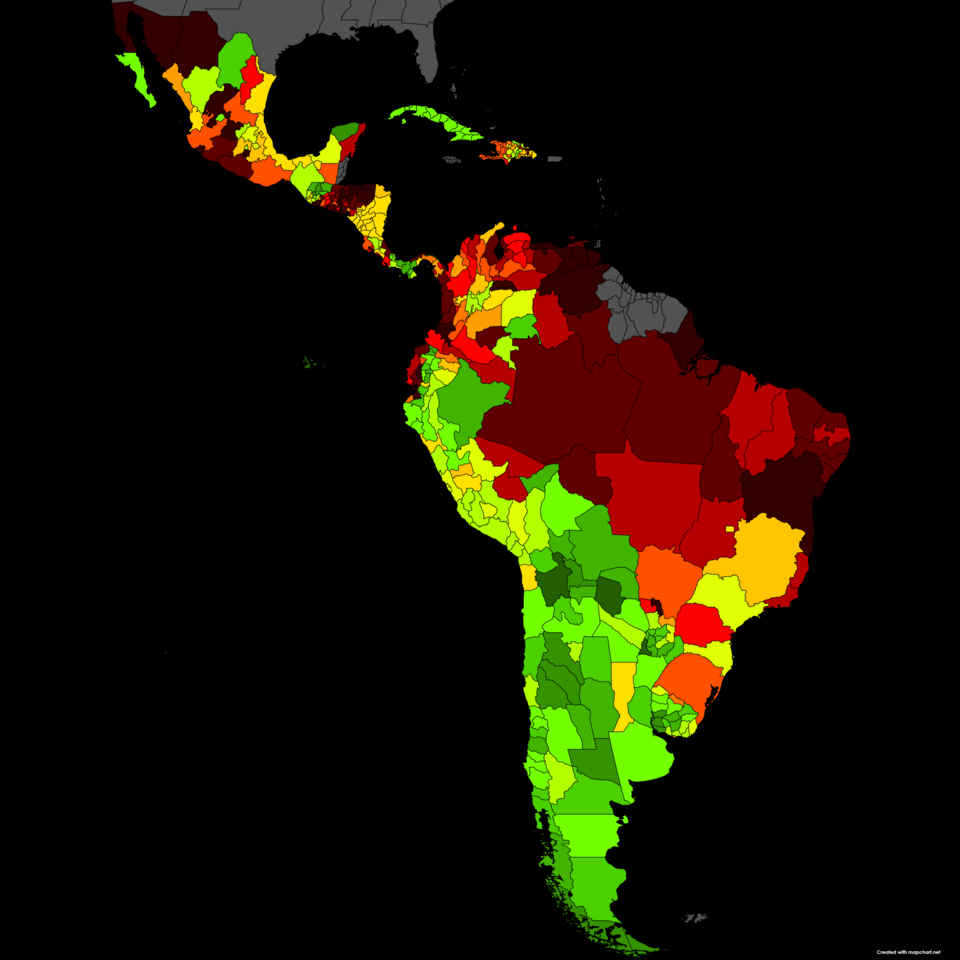

<p style="font-size:24px;text-align:justify;">Latinoamérica suele ser señalada como una de las regiones con mayores niveles de violencia del mundo, cuenta con una combinación de factores sociales, económicos e institucionales que han generado diferencias importantes entre países en términos de criminalidad y homicidios. Sin embargo, existe un debate constante acerca del papel que desempeña la disponibilidad de armas de fuego dentro de estos niveles de violencia. El dia de hoy exploraremos con el conjunto de datos Global Gun Violence & Civilian Firearms, la relación entre la posesión civil de armas y las tasas de homicidio observadas en distintos países de Latinoamérica, junto a otras variables socioeconomicas y demográficas (obtenidas por el banco mundial),esto con el objetivo de buscar patrones, tendencias y correlaciones que permitan comprender mejor los elementos vinculados a la incidencia de homicidios y al uso de armas de fuego.</p>

<h2 style="margin-bottom:0;size:30px;">Para empezar...</h2>
<h3 style="margin-bottom:0;margin-top:0;size:28px;">¿Con que estaremos trabajando? | Base de datos | Tablas de datos a usar</h3>
<p style="size:26px;">Para comenzar con la busqueda de datos, de las 4 tablas de datos, usaremos solo 3:</p>

| Archivo | Filas | Resumen |
|----------|----------:|----------|
| firearm_homicides_country_year.csv | 3,120 | Tasa de homicidios con arma de fuego por país y año (2000-2024). |
| civilian_firearms_2017.csv | 230 | Pais/ region (Small Arms Survey 2017)|
|country_gun_profile.csv | 217 | Una fila por pais, lista para un scatterplot o un mapa|

La 4ta tabla > homicide_long_run_western_europe.csv no nos servira pues, al ser un estudio echor para europa occidental, no tendra correlación / uso para estudio sobre latinoamérica.
Vamos a comprobar los componentes que trae cada tabla y poder empezar:


## 📄 `firearm_homicides_country_year.csv`

Panel país-año que combina indicadores de homicidios, armas de fuego y variables socioeconómicas provenientes del Banco Mundial.

### Identificación

| Columna | Tipo | Descripción |
|----------|----------|----------|
| iso3 | string | Código ISO 3166-1 alpha-3 del país |
| country | string | Nombre del país |
| region | string | Región según el Banco Mundial |
| income_group | string | Grupo de ingreso según el Banco Mundial |
| year | numeric | Año de observación |

### Indicadores de homicidio

| Columna | Tipo | Descripción |
|----------|----------|----------|
| homicide_rate | numeric | Homicidios intencionales por cada 100,000 habitantes |
| homicides | numeric | Número total de homicidios intencionales |
| homicides_total_est | numeric | Estimación de homicidios a partir de población y tasa de homicidios |
| firearm_homicide_rate | numeric | Homicidios cometidos con armas de fuego por cada 100,000 habitantes |
| firearm_homicides | numeric | Número total de homicidios cometidos con armas de fuego |
| firearm_share_of_homicides_pct | numeric | Porcentaje de homicidios cometidos con armas de fuego |

### Indicadores por sexo

| Columna | Tipo | Descripción |
|----------|----------|----------|
| female_homicide_rate | numeric | Tasa de homicidios de mujeres por cada 100,000 habitantes |
| male_homicide_rate | numeric | Tasa de homicidios de hombres por cada 100,000 habitantes |
| ipv_female_victim_rate | numeric | Mujeres asesinadas por pareja íntima por cada 100,000 mujeres |
| ipv_male_victim_rate | numeric | Hombres asesinados por pareja íntima por cada 100,000 hombres |

### Armas de fuego

| Columna | Tipo | Descripción |
|----------|----------|----------|
| seized_arms_illicit_origin_pct | numeric | Porcentaje de armas ilícitas rastreadas cuyo origen pudo determinarse |

### Variables socioeconómicas

| Columna | Tipo | Descripción |
|----------|----------|----------|
| population | numeric | Población total |
| gdp_per_capita_usd | numeric | PIB per cápita (USD corrientes) |
| gini_index | numeric | Índice de desigualdad de Gini |
| unemployment_pct | numeric | Tasa de desempleo |
| urban_population_pct | numeric | Porcentaje de población urbana |
| male_15_64_share_pct | numeric | Proporción de hombres de 15 a 64 años |
| military_spending_pct_gdp | numeric | Gasto militar como porcentaje del PIB |
| secondary_school_enrollment_pct | numeric | Tasa bruta de matriculación en educación secundaria |

## 📄 `civilian_firearms_2017.csv`

Información sobre la posesión civil de armas de fuego por país, basada en las estimaciones del Small Arms Survey para 2017.

### Identificación geográfica

| Columna | Tipo | Descripción |
|----------|----------|----------|
| location | string | País o territorio según la nomenclatura del Small Arms Survey |
| iso3 | string | Código ISO3 del país o territorio |

### Indicadores de armas de fuego

| Columna | Tipo | Descripción |
|----------|----------|----------|
| firearms_per_100_people | numeric | Estimación de armas de fuego en posesión civil por cada 100 habitantes (2017) |
| civilian_firearms | numeric | Número total estimado de armas de fuego en posesión civil (lícitas e ilícitas) |
| registered_firearms | numeric | Número estimado de armas registradas ante las autoridades |
| unregistered_firearms | numeric | Número estimado de armas no registradas |

### Información demográfica

| Columna | Tipo | Descripción |
|----------|----------|----------|
| population_2017 | numeric | Población utilizada para el cálculo de armas por cada 100 habitantes |

### Clasificación regional

| Columna | Tipo | Descripción |
|----------|----------|----------|
| sas_region | string | Región utilizada por el Small Arms Survey |
| sas_subregion | string | Subregión utilizada por el Small Arms Survey |

### Metodología

| Columna | Tipo | Descripción |
|----------|----------|----------|
| computation_method | string | Método utilizado para estimar la cantidad de armas de fuego, incluyendo encuestas, estimaciones de expertos o comparaciones con países similares |

## 📄 `country_gun_profile.csv`

Base consolidada con una fila por país que integra indicadores de posesión de armas de fuego, homicidios y variables socioeconómicas. Este conjunto resulta especialmente útil para análisis exploratorios, correlaciones y visualizaciones comparativas entre países.

### Identificación geográfica

| Columna | Tipo | Descripción |
|----------|----------|----------|
| iso3 | string | Código ISO3 del país |
| country | string | Nombre del país |
| region | string | Región según el Banco Mundial |
| income_group | string | Grupo de ingreso según el Banco Mundial |
| latitude | numeric | Latitud aproximada de la capital |
| longitude | numeric | Longitud aproximada de la capital |

### Indicadores de armas de fuego

| Columna | Tipo | Descripción |
|----------|----------|----------|
| firearms_per_100_people | numeric | Armas de fuego en posesión civil por cada 100 habitantes (2017) |
| civilian_firearms | numeric | Total estimado de armas de fuego en posesión civil (2017) |
| registered_firearms | numeric | Total estimado de armas registradas (2017) |

### Indicadores recientes de homicidio

| Columna | Tipo | Descripción |
|----------|----------|----------|
| latest_homicide_rate | numeric | Tasa de homicidios más reciente disponible por cada 100,000 habitantes |
| latest_homicide_rate_year | numeric | Año correspondiente a la tasa de homicidios más reciente |
| latest_firearm_homicide_rate | numeric | Tasa de homicidios cometidos con armas de fuego más reciente disponible |
| latest_firearm_homicide_rate_year | numeric | Año correspondiente a la tasa de homicidios con armas de fuego más reciente |

### Promedios históricos (2013-2022)

| Columna | Tipo | Descripción |
|----------|----------|----------|
| avg_2013_2022_homicide_rate | numeric | Promedio de la tasa de homicidios entre 2013 y 2022 |
| avg_2013_2022_firearm_homicide_rate | numeric | Promedio de la tasa de homicidios con armas de fuego entre 2013 y 2022 |
| avg_2013_2022_firearm_share_of_homicides_pct | numeric | Promedio del porcentaje de homicidios cometidos con armas de fuego entre 2013 y 2022 |

### Variables socioeconómicas

| Columna | Tipo | Descripción |
|----------|----------|----------|
| population_2017 | numeric | Población estimada en 2017 |
| gdp_per_capita_usd_2017 | numeric | PIB per cápita en dólares corrientes (2017) |
| gini_index_2017 | numeric | Índice de desigualdad de Gini (2017) |
| urban_population_pct_2017 | numeric | Porcentaje de población urbana (2017) |

<p style="font-size:20px;text-align:justify;">Con estos conjuntos de datos es posible identificar variables socioeconómicas y demográficas relevantes para el análisis, así como establecer relaciones entre distintas fuentes mediante identificadores únicos, como el código ISO3, o llaves de emparejamiento como (iso3, location) y/o (iso3, region). Además, se dispone de indicadores históricos, variables agregadas y métricas resumidas que permiten construir una visión más amplia del contexto asociado a los homicidios y la posesión de armas de fuego, adicional de informacion para un año en especifico en 2017. Una vez comprendida la estructura general de los datos y las relaciones existentes entre los distintos archivos, procederemos a realizar una evaluación técnica del dataset con el fin de conocer su composición, calidad y comportamiento interno antes de iniciar el análisis exploratorio.</p>